# 03．資源時間表：600 ms 窗口中的 UE 與 Tag

**狀態：2026-11-02 人工審核通過；核心已搬入 `src/timeline`，本 Notebook 匯入同一份程式。**

閱讀順序：[資料契約](../src/timeline/contracts.py) → [核心邏輯](../src/timeline/resource_timeline.py) → [繪圖](../src/timeline/plotting.py)。設定、說明、HTML 表格與斷言保留在本 Notebook。

本單元將展示共用 600 ms 外層窗口，如何依各 Node 的 UE 占用產生不同的 Tag 可用區間。
表格與圖表示資源可用時間，不代表實際完成的資料傳送。

## 已定案的模型

- 所有 Node 共用外層窗口 ID 與起迄，首窗從全域 0 開始；後續起點與間隔由情境提供。
- 每個 Node、每個窗口都有 UE 前段，比例均勻抽取 60%～75%，向上取整至整毫秒，再轉成整數奈秒。
- 每窗 UE 區段只使用 UL 或 DL，一次選一個方向，各 50%。
- Node／Window／時長／方向分開獨立抽樣，情境 seed 可重現；抽到相同結果不重抽。
- UE 結束後的剩餘時間提供給 Tag 的 Paging、D2R 與 Guard。
- 不在本單元實作完整 Engine、能量帳本、服務認列或排程策略。

## 來源

- [原始 System Model](../ReferDoc/Plan/main.pdf)：第 10–11 頁的時序圖與限制式。
- [決策紀錄](../ReferDoc/Plan/R-01_System_Model_and_Baseline_Decision_Record.md)：第 34.6–34.11 節。
- [整合設計](../docs/architecture/resource-timeline-design.md)。
- [逐 cell 原型計畫](../docs/architecture/resource-timeline-notebook-plan.md)。

原始來源為 `/home/tonywang/115-1/system_model_mod/version_1/main.pdf`，與專案副本雜湊相同。
UE 比例、UL／DL 機率與取整方式是後續確認的模擬假設，不冒稱原始圖或 3GPP 規範已定義這些數值。


## 1．載入既有拓撲

沿用 iab 模組取得 Node ID，不複製拓撲核心。預期展示既有五個 Node。

來源：[對應設計或程式](../src/iab/topology.py)。


In [1]:
from dataclasses import dataclass, asdict, replace
from enum import Enum
from pathlib import Path
import csv
import hashlib
import json
import math
import random
import sys

import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent

if not (ROOT / 'src').is_dir():
    raise ValueError('Run from the project root or notebooks directory')

if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from iab.topology import build_topology, example_config


## 2．集中列出情境設定

固定模型值如下。起點範例只作 synthetic 情境，不代表正式間隔分布。資料單位保存為 ns，顯示時才轉成 ms。

來源：[對應設計或程式](../ReferDoc/Plan/R-01_System_Model_and_Baseline_Decision_Record.md)。


In [2]:
from timeline.contracts import WINDOW_NS, UEDirection, ResourceConfig, NodeResource, ResourceWindow, CurrentResource


## 3．驗證輸入

檢查 tuple、Node ID 唯一性、整數 ns 起點、首窗 0、起點遞增與窗口不重疊。拒絕 bool、負值、缺少起點與錯誤型別；錯誤不得產生部分 Trace。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [3]:
from timeline.resource_timeline import validate_resource_config


## 4．建立可重現的獨立抽樣

以情境 seed、Node ID、Window ID、抽樣種類區分亂數身分。資源、通道、PHY、Policy 的亂數來源分開，不改全域 RNG。相同結果是合法巧合。

來源：[對應設計或程式](../ReferDoc/Plan/R-01_System_Model_and_Baseline_Decision_Record.md)。


In [4]:
from timeline.resource_timeline import resource_rng, round_ue_duration_ns


## 5．產生 UE 與 Tag 資源區間

先抽連續比例，再計算 ceil(600*r) ms 並轉成 ns。UE 區間為 [start,ue_end)，Tag 為 [ue_end,end)。連續均勻抽樣後取整不同於整數均勻抽樣。

來源：[對應設計或程式](../docs/architecture/resource-timeline-design.md)。


In [5]:
from timeline.resource_timeline import build_timeline


## 6．整理表格

外層摘要列出窗口 ID、起迄及間隔；Node 明細列出方向、UE 時長、Tag 起點與可用預算。表格只從同一快照取得資料。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [6]:
from timeline.resource_timeline import resource_rows

def display_table(rows):
    from html import escape
    from IPython.display import HTML
    column_names = tuple(rows[0]) if rows else ()
    header_html = ''.join('<th>'+escape(str(column_name))+'</th>' for column_name in column_names)
    body_html = ''.join('<tr>'+''.join('<td>'+escape(str(resource_row[column_name]))+'</td>' for column_name in column_names)+'</tr>' for resource_row in rows)
    display(HTML('<table><thead><tr>'+header_html+'</tr></thead><tbody>'+body_html+'</tbody></table>'))


## 7．繪製時間表

每個 Node 一列，以不同顏色區分 UE 占用與 Tag 可用區間，標註 UL／DL。窗間空檔不得畫成 Tag 可用時間。

來源：[對應設計或程式](../ReferDoc/Plan/main.pdf)。


In [7]:
from timeline.plotting import plot_resources


## 8．執行小型情境

使用設定 cell 的 synthetic 起點與 seed。預期得到兩個 600 ms 窗口；各 Node 的實際抽樣值須由執行產生，不預填成觀測結果。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


window_id,start_ms,end_ms
0,0.0,600.0
1,800.0,1400.0


window_id,node_id,direction,start_ns,ue_end_ns,end_ns,raw_duration_ms,ue_duration_ms,tag_budget_ms
0,Node-1,UL,0,398000000,600000000,397.58059653591965,398,202
0,Node-2,UL,0,380000000,600000000,379.5245715458021,380,220
0,Node-3,DL,0,429000000,600000000,428.4971385713133,429,171
0,Node-4,UL,0,438000000,600000000,437.0396667526655,438,162
0,Node-5,UL,0,361000000,600000000,360.44462050693534,361,239
1,Node-1,UL,800000000,1187000000,1400000000,386.55453930955605,387,213
1,Node-2,UL,800000000,1192000000,1400000000,391.00226558347504,392,208
1,Node-3,DL,800000000,1168000000,1400000000,367.6482603329816,368,232
1,Node-4,UL,800000000,1207000000,1400000000,406.3939641045087,407,193
1,Node-5,DL,800000000,1178000000,1400000000,377.329625132116,378,222


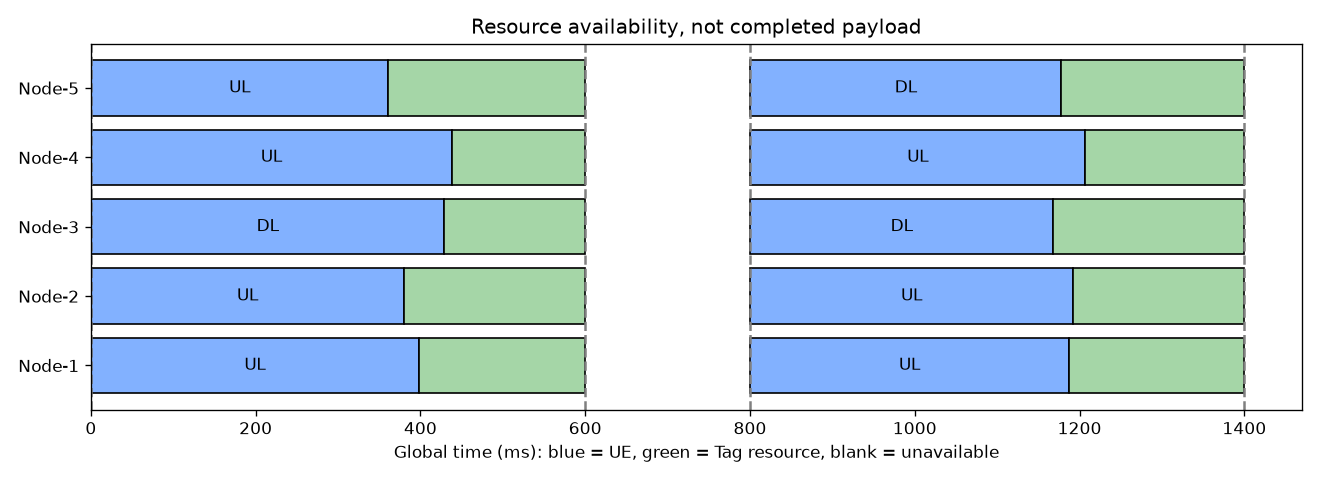

In [8]:
# Explicit synthetic inputs: the 200 ms gap is not a research default.
topology = build_topology(example_config())
config = ResourceConfig('resource-timeline-demo', 42,
                        tuple(node.node_id for node in topology.config.iab_nodes),
                        (0, 800_000_000))
windows = build_timeline(config)
display_table([dict(window_id=window.window_id, start_ms=window.start_ns/1_000_000,
              end_ms=window.end_ns/1_000_000) for window in windows])
display_table(resource_rows(windows))
figure = plot_resources(windows)
from io import BytesIO
from IPython.display import Image
image_buffer = BytesIO()
figure.savefig(image_buffer, format="png", dpi=120)
display(Image(data=image_buffer.getvalue()))
plt.close(figure)


## 9．查看當前可見資源

由呼叫端提供 now_ns，不在此建立第二個時鐘。分別展示 UE 尚未結束、Tag 區間、窗口結束與窗間空檔。Policy-facing 結果不得含完整未來 Trace。

來源：[對應設計或程式](../ReferDoc/Plan/Codex_Handoff_Specification_Ambient_IoT_DES.md)。


In [9]:
from timeline.resource_timeline import current_resource


## 10．核對取整與時間邊界

獨立預期值：398.2 ms → 399 ms → 399000000 ns；剩餘 201 ms。另驗證 60%／75%、整毫秒附近、UE_END 及 WINDOW_END。下方斷言與外部測試核對這些預期值。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [10]:
assert round_ue_duration_ns(398.2) == 399_000_000
assert round_ue_duration_ns(360) == 360_000_000
assert round_ue_duration_ns(450) == 450_000_000
node_resource = windows[0].nodes[0]
assert current_resource(windows, node_resource.node_id, node_resource.ue_end_ns-1).status == 'UE_OCCUPIED'
assert current_resource(windows, node_resource.node_id, node_resource.ue_end_ns).status == 'TAG_AVAILABLE'
assert current_resource(windows, node_resource.node_id, node_resource.end_ns).status == 'NO_WINDOW'
display(current_resource(windows, node_resource.node_id, node_resource.ue_end_ns))
print('Rounding and half-open interval assertions passed')


CurrentResource(node_id='Node-1', now_ns=398000000, status='TAG_AVAILABLE', window_id=0, tag_start_ns=398000000, window_end_ns=600000000)

Rounding and half-open interval assertions passed


## 11．核對重現性與查詢順序

相同設定／seed 應重現；調換 Node 查詢順序或增加 Policy RNG 呼叫不得改變資源 Trace。保留合法重複結果，不以少量窗口宣稱已量測出 50／50 比例。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [11]:
global_rng_before = random.getstate()
assert build_timeline(config) == windows
reordered_windows = build_timeline(replace(config, node_ids=tuple(reversed(config.node_ids))))
def index_resources_by_window_and_node(resource_windows):
    return {(window.window_id, node_resource.node_id): node_resource
            for window in resource_windows for node_resource in window.nodes}
assert index_resources_by_window_and_node(reordered_windows) == index_resources_by_window_and_node(windows)
assert random.getstate() == global_rng_before
print('Seed, traversal-order and global RNG isolation assertions passed')


Seed, traversal-order and global RNG isolation assertions passed


## 12．示範通道窗口交接

每個共用窗口只宣告一次既有 ChannelModel.window。不同 Node 的 Tag 起點不應重開通道或重抽本窗品質。此示範不等同完整事件引擎。

來源：[對應設計或程式](../src/channel/channel_model.py)。


In [12]:
from channel.contracts import ChannelConfig, PowerLevel
from channel.channel_model import ChannelModel
channel_model = ChannelModel(ChannelConfig(), topology)
for window in windows:
    channel_model.window(window.window_id, PowerLevel.LOW)
    example_tag = topology.tags[0]
    first_link = channel_model.link(window.window_id, example_tag.tag_id)
    assert channel_model.link(window.window_id, example_tag.tag_id) == first_link
print('Shared channel window identity and repeated-query assertions passed')


Shared channel window identity and repeated-query assertions passed


## 13．匯出結果

匯出必須由使用者明確執行此 cell。規劃輸出 JSON／CSV／PNG／SVG；下方明確呼叫才會匯出並覆寫同名檔案；失敗可留下部分檔案，執行前備份需保留的同名檔案。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [13]:
from timeline.resource_timeline import export_resources


### 明確執行匯出
將 EXPORT_RESULTS 改成 True 才會寫入檔案。匯出會覆寫同名結果；請先備份。


In [14]:
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    export_resources(windows, ROOT / "notebooks/artifacts/resource-timeline")


## 14．回顧與人工導讀

依序檢視輸入、區間生成、表格／圖、觀測隔離及驗收結果。未執行的 cell、未通過的斷言與未確認的行為保持明示。本單元已經人工接受；核心 .py 路徑見開頭，後續修改仍須核對測試與實際行為。

來源：[對應設計或程式](../docs/architecture/resource-timeline-notebook-plan.md)。


In [15]:
assert len(windows) == 2 and len(resource_rows(windows)) == 10
print('Notebook demonstrations passed. Review code, external tests and limits before human acceptance.')


Notebook demonstrations passed. Review code, external tests and limits before human acceptance.
